# TASK 3 - CLUSTERING

## Import Libraries

In [1]:
import pandas as pd
import pandas
import seaborn as sns
import matplotlib.pyplot as plt 
from pyclustering.cluster.kmeans import kmeans
from pyclustering.cluster.kmedoids import kmedoids
from pyclustering.cluster.xmeans import xmeans
from pyclustering.cluster.dbscan import dbscan
from pyclustering.cluster.optics import optics
from pyclustering.cluster.somsc import somsc
from pyclustering.utils import read_sample
from pyclustering.cluster.center_initializer import kmeans_plusplus_initializer
from pyclustering.utils.metric import distance_metric, type_metric
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.cluster import AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from cuml.cluster import KMeans as cuKMeans, DBSCAN as cuDBSCAN, AgglomerativeClustering as cuAgglomerativeClustering
import numpy as np
import warnings
import logging
import pickle
from datetime import datetime
from typing import Tuple, Dict, Any
from cuml.preprocessing import StandardScaler
from sklearn.utils import shuffle
import itertools as itertools

np.warnings = warnings

In [2]:
def __transform_single_features(dataset: pandas.DataFrame, transformation: str) -> Tuple[
    pandas.DataFrame, Dict[str, Any]]:
    match transformation:
        case "standard":
            transformed_dataset = dataset.copy().select_dtypes(exclude=["object", "category", "bool", "datetime64"])
            transformations = dict()

            for feature in transformed_dataset.columns:
                transformations[feature] = StandardScaler()
                transformed_feature = transformations[feature].fit_transform(transformed_dataset[[feature]]).squeeze()
                transformed_dataset = transformed_dataset.astype({feature: transformed_feature.dtype})
                transformed_dataset.loc[:, feature] = transformed_feature
        case _:
            raise ValueError(f"Unknown transformation: {transformation}")

    return transformed_dataset, transformations


def center_and_scale(dataset: pandas.DataFrame) -> Tuple[pandas.DataFrame, Dict[str, Any]]:
    """Shifts data to the origin: removes mean and scales by standard deviation all numeric features. Returns a copy of the dataset."""
    return __transform_single_features(dataset, "standard")

In [2]:
from typing import Dict, Any, Tuple, Optional, List
import pandas as pd

def reverse_center_and_scale(
    transformed_dataset: pd.DataFrame,
    transformations: Dict[str, Any],
    excluded_features: Optional[List[str]] = None
) -> pd.DataFrame:
    """
    Reverts the centering and scaling transformation applied to the dataset.

    Parameters:
    - transformed_dataset: The DataFrame containing the transformed data.
    - transformations: A dictionary with the scalers for each feature.
    - excluded_features: An optional list of features to exclude from the reverse transformation.

    Returns:
    - A DataFrame with the original (unscaled) data.
    """
    excluded_features = excluded_features or []  # Default to an empty list if None

    original_dataset = transformed_dataset.copy()

    for feature, scaler in transformations.items():
        if feature in original_dataset.columns and feature not in excluded_features:
            # Revert the transformation using the scaler's inverse_transform method
            original_feature = scaler.inverse_transform(original_dataset[[feature]])
            original_dataset.loc[:, feature] = original_feature.squeeze()

    return original_dataset


In [3]:
dict_scaler = None
df = pd.read_csv('../dataset/cleaned.csv')
with open("transformations/dict_scalers.pkl", "rb") as f:
    dict_scaler = pickle.load(f)
    
df = reverse_center_and_scale(df, dict_scaler['scalers'],['uci_points', 'profile', 'position', 'weight', 'height', 'cyclist_age_range', 'cyclist_points_range', 'region'])
df

/tmp/ipykernel_4569/165574058.py:28: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[3.79021988 3.79021988 3.79021988 ... 3.79021988 3.79021988 3.79021988]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  original_dataset.loc[:, feature] = original_feature.squeeze()
/tmp/ipykernel_4569/165574058.py:28: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[5.48769197 5.48769197 5.48769197 ... 2.9444066  2.9444066  2.9444066 ]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  original_dataset.loc[:, feature] = original_feature.squeeze()


,points,uci_points,length,climb_total,profile,startlist_quality,average_temperature,date,position,cyclist,...,mode_position_for_-1.0,profile_score_4.0,mode_position_for_4.0,mode_points,mode_position,mode_startlist_quality,median_points,median_startlist,placement_points,placement_startlist_quality
0,80.0,100.0,196.0,11.570095,5.0,821.0,NaN,2016-09-03,0,robert-gesink,...,-1,2.000000,3,2.0,3.0,2.0,-0.106818,-0.384245,0.611283,0.863722
1,80.0,100.0,196.0,11.570095,5.0,821.0,NaN,2016-09-03,1,kenny-elissonde,...,-1,7.000000,0,2.0,3.0,2.0,-0.106818,-0.347065,0.955445,0.988797
2,80.0,100.0,196.0,11.570095,5.0,821.0,NaN,2016-09-03,2,egor-silin,...,-1,0.000000,3,1.0,0.0,2.0,-0.735134,-0.487821,0.920567,0.910897
3,80.0,100.0,196.0,11.570095,5.0,821.0,NaN,2016-09-03,3,george-bennett,...,-1,0.000000,0,1.0,0.0,2.0,-0.735134,-0.347065,0.936264,0.962458
4,80.0,100.0,196.0,11.570095,5.0,821.0,NaN,2016-09-03,4,simon-yates,...,-1,0.000000,3,1.0,3.0,2.0,0.312060,0.320862,1.112433,0.956625
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
380086,80.0,16.0,8.4,1.552215,1.0,878.0,NaN,2010-05-08,192,anders-lund-1,...,2,0.000000,0,2.0,2.0,2.0,-0.106818,-0.333786,1.089068,0.931043
380087,80.0,16.0,8.4,1.552215,1.0,878.0,NaN,2010-05-08,193,andrea-masciarelli,...,2,0.000000,2,2.0,2.0,2.0,-0.106818,-0.333786,1.000000,1.000000
380088,80.0,16.0,8.4,1.552215,1.0,878.0,NaN,2010-05-08,194,marco-corti,...,0,0.000000,-1,1.0,2.0,0.0,-0.735134,0.093794,1.000000,1.000000
380089,80.0,16.0,8.4,1.552215,1.0,878.0,NaN,2010-05-08,195,robbie-mcewen,...,2,0.166667,2,2.0,3.0,0.0,-0.106818,-0.113357,1.056988,-0.595697


In [5]:
normalized_df, normalization_scalers_df= center_and_scale(shuffle(df))
normalized_df

,points,uci_points,length,climb_total,profile,startlist_quality,average_temperature,position,cyclist_age,delta,...,mode_position_for_-1.0,profile_score_4.0,mode_position_for_4.0,mode_points,mode_position,mode_startlist_quality,median_points,median_startlist,placement_points,placement_startlist_quality
219306,0.959056,NaN,0.667837,-1.463469,-0.078673,-1.068309,NaN,-0.595568,-0.468107,-0.380220,...,-0.237999,-0.311242,-0.027948,0.600468,0.357065,0.518270,0.167161,0.024307,0.010024,-0.004295
297426,-0.662183,-0.762140,0.016317,0.573506,-0.078673,-0.220229,NaN,1.363267,-0.216176,0.380284,...,0.361373,-0.311242,0.608903,-0.429374,0.357065,0.518270,-0.771636,-0.185184,0.009741,0.005585
153114,-0.662183,NaN,0.037334,-1.463469,1.545422,0.336812,NaN,-0.489109,-0.216176,-0.092010,...,-0.237999,-0.311242,0.608903,-0.429374,-0.970296,0.518270,-0.771636,-0.185184,0.008583,-0.000686
121425,-0.013687,-0.621931,0.134335,0.325463,1.004057,-0.561339,NaN,0.426433,3.058932,1.704192,...,-0.837371,-0.311242,0.608903,0.600468,0.357065,0.518270,0.167161,0.825609,0.007079,0.005163
367420,0.418643,NaN,0.102001,-0.077117,-0.078673,2.026714,NaN,-1.234318,-0.216176,-0.744667,...,1.560116,-0.311242,-0.664798,0.600468,1.020746,-1.176637,-0.145771,0.595169,0.011470,0.015155
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249298,-0.013687,0.555826,-1.040988,1.016400,1.545422,-0.013686,NaN,0.213516,0.035756,1.631675,...,-0.837371,-0.311242,0.608903,0.600468,0.357065,0.518270,0.167161,-0.195659,0.009669,0.004245
10887,-0.013687,NaN,0.789088,-0.229414,-0.620038,0.136528,NaN,-0.510401,-0.971970,-0.744667,...,1.560116,-0.311242,1.245753,0.600468,1.020746,0.518270,0.167161,0.003358,0.005728,-0.018080
277886,-0.662183,NaN,-0.037033,-1.463469,-1.702767,-1.409419,NaN,-1.255610,1.043481,-0.744667,...,1.560116,-0.311242,1.245753,-0.429374,1.020746,1.365723,-0.771636,1.291726,0.009644,-0.022227
26483,-0.013687,-0.621931,-0.108167,0.588624,-0.078673,-0.483103,NaN,1.640059,-0.468107,1.525688,...,0.960744,-0.311242,0.608903,0.600468,1.020746,-1.176637,0.167161,1.076998,0.021696,-0.020940


Pick the 50000 samples from shuffled data

In [6]:
# reduce dataset size
normalized_df = normalized_df.head(50000)
normalized_df

,points,uci_points,length,climb_total,profile,startlist_quality,average_temperature,position,cyclist_age,delta,...,mode_position_for_-1.0,profile_score_4.0,mode_position_for_4.0,mode_points,mode_position,mode_startlist_quality,median_points,median_startlist,placement_points,placement_startlist_quality
219306,0.959056,NaN,0.667837,-1.463469,-0.078673,-1.068309,NaN,-0.595568,-0.468107,-0.380220,...,-0.237999,-0.311242,-0.027948,0.600468,0.357065,0.518270,0.167161,0.024307,0.010024,-0.004295
297426,-0.662183,-0.762140,0.016317,0.573506,-0.078673,-0.220229,NaN,1.363267,-0.216176,0.380284,...,0.361373,-0.311242,0.608903,-0.429374,0.357065,0.518270,-0.771636,-0.185184,0.009741,0.005585
153114,-0.662183,NaN,0.037334,-1.463469,1.545422,0.336812,NaN,-0.489109,-0.216176,-0.092010,...,-0.237999,-0.311242,0.608903,-0.429374,-0.970296,0.518270,-0.771636,-0.185184,0.008583,-0.000686
121425,-0.013687,-0.621931,0.134335,0.325463,1.004057,-0.561339,NaN,0.426433,3.058932,1.704192,...,-0.837371,-0.311242,0.608903,0.600468,0.357065,0.518270,0.167161,0.825609,0.007079,0.005163
367420,0.418643,NaN,0.102001,-0.077117,-0.078673,2.026714,NaN,-1.234318,-0.216176,-0.744667,...,1.560116,-0.311242,-0.664798,0.600468,1.020746,-1.176637,-0.145771,0.595169,0.011470,0.015155
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
312073,-0.662183,NaN,0.446353,0.252674,-0.078673,-0.251524,NaN,0.873558,-0.720038,0.240827,...,-0.837371,-0.311242,-1.301648,0.600468,1.020746,0.518270,1.575357,-1.808738,0.009741,0.005585
230068,-0.662183,-0.285429,0.231335,-0.659429,-0.620038,-0.893060,NaN,-0.467818,0.035756,0.201779,...,-0.837371,2.394748,1.245753,0.600468,1.020746,0.518270,0.167161,-0.462759,0.007551,-0.016314
328337,-0.013687,0.555826,0.441503,0.287389,-0.078673,-0.498750,NaN,2.087184,-1.475832,0.737293,...,-0.837371,-0.311242,0.608903,0.600468,0.357065,0.518270,0.167161,-0.195659,0.011233,-0.001369
176311,-0.662183,-0.762140,0.380069,0.528153,-0.078673,-0.699035,NaN,2.129767,-0.720038,1.287682,...,0.361373,-0.311242,-0.027948,-0.429374,-0.970296,-1.176637,-0.771636,0.825609,0.009741,0.005585


Define the type of clusters we want to analyse.

In [21]:
features_list = [
    # Race Characteristics
    [
        'length',
        'climb_total',
        'profile',
        'startlist_quality',
    ],
    # Cyclist Attributes
    [
        'cyclist_age',
        'weight',
        'height',
        'region',
        'points',
        "cyclist_age_range", 
        "cyclist_points_range"
    ],
    # Total features
    [
        'length',
        'climb_total',
        'profile',
        'startlist_quality',
        'cyclist_age',
        'weight',
        'height',
        'region',
        'points',
        'position',
        "cyclist_age_range", 
        "cyclist_points_range"
    ]
]

In [ ]:
normalized_df = normalized_df.filter([item for sublist in features_list for item in sublist])

Define all the parameters that we want to try

In [8]:
maximum_distance = abs(normalized_df.max() - normalized_df.min()).sum().item()
average_concentration = normalized_df.shape[0] / maximum_distance

models = {

    "cuml_kmeans": [
        {"clusters": clusters} for clusters in list(range(2, 9, 2)) + [16, 32]
    ],
    "cuml_dbscan": [
        {"eps": eps} for eps in (average_concentration * np.array([10, 5, 2.5, 1, 0.1, 0.01, 0.0001])) 
    ],
    "cuml_hierarchical": [
        {"clusters": clusters, "linkage": linkage, "affinity": affinity}
        for clusters, linkage, affinity in itertools.product(
            list(range(2, 9, 2)) + [16, 32], 
            ["ward", "complete"], 
            ["euclidean", "manhattan"]
        ) if not (linkage == 'ward' and affinity == 'manhattan')
    ],
    "gmm": [
        {"clusters": clusters, "covariance_type": covariance_type}
        for clusters, covariance_type in itertools.product(
            list(range(2, 9, 2)) + [16, 32], 
            ["full", "tied"]
        )
    ],
    "som": [
        {"clusters": clusters} for clusters in list(range(2, 9, 2)) + [16, 32]
    ]
}

#### **1. Silhouette Coefficient**

The Silhouette Coefficient measures how similar an object is to its own cluster compared to other clusters. It ranges from **-1 to 1**, where:

- **1**: The object is well-matched to its own cluster and poorly matched to neighboring clusters.
- **0**: The object lies on or very close to the decision boundary between two neighboring clusters.
- **Negative values**: The object might have been assigned to the wrong cluster.

The coefficient is calculated as:


$$s = \frac{b - a}{\max(a, b)}$$


Where:

- \(a\): Average distance between the object and all other points in the same cluster.
- \(b\): Average distance between the object and all points in the nearest cluster.

A higher Silhouette Coefficient indicates better-defined clusters. :contentReference[oaicite:0]{index=0}

---

#### **2. Calinski-Harabasz Index**

Also known as the Variance Ratio Criterion, the Calinski-Harabasz Index evaluates the ratio of the sum of between-cluster dispersion to within-cluster dispersion. A **higher score** signifies that the clusters are dense and well-separated.

The index is defined as:

$$
\text{CH} = \frac{\text{trace}(B_k) / (k - 1)}{\text{trace}(W_k) / (n - k)}
$$

Where:

- \(B_k\): Between-cluster dispersion matrix.
- \(W_k\): Within-cluster dispersion matrix.
- \(k\): Number of clusters.
- \(n\): Total number of data points.

This metric favors models with well-defined clusters. :contentReference[oaicite:1]{index=1}

---

#### **3. Davies-Bouldin Index**

The Davies-Bouldin Index assesses the average similarity ratio of each cluster with its most similar cluster. A **lower score** indicates better clustering quality, as it signifies that clusters are compact and well-separated.

It is calculated as:

$$
\text{DB} = \frac{1}{k} \sum_{i=1}^k \max_{j \neq i} \left( \frac{s_i + s_j}{d_{ij}} \right)
$$

Where:

- \(s_i\): Average distance between each point in cluster \(i\) and the centroid of cluster \(i\).
- \(d_{ij}\): Distance between the centroids of clusters \(i\) and \(j\).
- \(k\): Number of clusters.

Lower Davies-Bouldin Index values indicate that clusters are compact, with lower intra-cluster distances, and well-separated, with higher inter-cluster distances. :contentReference[oaicite:2]{index=2}

---

#### **4. Cohesion**

Cohesion measures the compactness of a cluster, indicating how closely related the data points within a cluster are. It is often computed as the **sum of squared distances between each point and the centroid of its cluster**.

Formally:

$$
\text{Cohesion} = \sum_{i=1}^k \sum_{x \in C_i} \| x - \mu_i \|^2
$$

Where:

- \(k\): Number of clusters.
- \(C_i\): Set of points in cluster \(i\).
- \(\mu_i\): Centroid of cluster \(i\).

Lower cohesion values indicate that the points within clusters are closely grouped together, reflecting higher intra-cluster similarity.

---


In [9]:
metrics = ["silhouette", "calinski_harabasz", "davies_bouldin", "cohesion"]

In [10]:
# Set up logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')

# Function to train clusters
def train_clusters(data, models, features_list):
    fitted_models = {}

    for features in features_list:
        logging.info(f"Processing feature subset: {features}")
        data_subset = data[features].values
        for model_name, hyperparam_list in models.items():
            for hyperparam in hyperparam_list:
                logging.info(f"Training model: {model_name} with hyperparams: {hyperparam}")

                # Initialize clustering model
                if model_name == "kmeans":
                    initial_centers = kmeans_plusplus_initializer(data_subset, hyperparam['clusters']).initialize()
                    cluster_model = kmeans(data_subset, initial_centers, metric=distance_metric(type_metric.EUCLIDEAN))
                elif model_name == "kmedoids":
                    initial_medoids = kmeans_plusplus_initializer(data_subset, hyperparam['clusters']).initialize()
                    cluster_model = kmedoids(data_subset, initial_medoids, metric=distance_metric(type_metric.EUCLIDEAN))
                elif model_name == "xmeans":
                    initial_centers = kmeans_plusplus_initializer(data_subset, hyperparam['clusters']).initialize()
                    cluster_model = xmeans(data_subset, initial_centers, tolerance=['tolerance'])
                elif model_name == "dbscan":
                    cluster_model = dbscan(data_subset, hyperparam['eps'], metric=distance_metric(type_metric.EUCLIDEAN))
                elif model_name == "optics":
                    cluster_model = optics(data_subset, hyperparam['eps'], hyperparam['min_samples'], metric=distance_metric(type_metric.EUCLIDEAN))
                elif model_name == "hierarchical":
                    cluster_model = AgglomerativeClustering(n_clusters=hyperparam['clusters'], metric=hyperparam['affinity'], linkage=hyperparam['linkage'])
                    labels = cluster_model.fit_predict(data_subset)
                    clusters = [np.where(labels == i)[0].tolist() for i in range(hyperparam['clusters'])]
                elif model_name == "gmm":
                    cluster_model = GaussianMixture(n_components=hyperparam['clusters'], covariance_type=hyperparam['covariance_type'])
                    labels = cluster_model.fit_predict(data_subset)
                    clusters = [np.where(labels == i)[0].tolist() for i in range(hyperparam['clusters'])]
                elif model_name == "cuml_kmeans":
                    cluster_model = cuKMeans(n_clusters=hyperparam['clusters'], random_state=0)
                    cluster_model.fit(data_subset)
                    labels = cluster_model.labels_
                    clusters = [np.where(labels == i)[0].tolist() for i in range(hyperparam['clusters'])]
                elif model_name == "cuml_dbscan":
                    cluster_model = cuDBSCAN(eps=hyperparam['eps'])
                    labels = cluster_model.fit_predict(data_subset)
                    clusters = [np.where(labels == i)[0].tolist() for i in np.unique(labels) if i != -1]
                elif model_name == "cuml_hierarchical":
                    cluster_model = cuAgglomerativeClustering(n_clusters=hyperparam['clusters'], metric=hyperparam['affinity'])
                    labels = cluster_model.fit_predict(data_subset)
                    clusters = [np.where(labels == i)[0].tolist() for i in range(hyperparam['clusters'])]
                elif model_name == "som":
                    cluster_model = somsc(data_subset, hyperparam['clusters'])
                    
                else:
                    raise ValueError(f"Unsupported model: {model_name}")

                # Train the clustering model (if applicable)
                if model_name not in ["hierarchical", "gmm", "cuml_kmeans", "cuml_dbscan", "cuml_hierarchical"]:
                    cluster_model.process()
                    clusters = cluster_model.get_clusters()

                # Convert clusters to labels for metric calculation
                labels = np.zeros(data_subset.shape[0], dtype=int)
                for cluster_id, cluster_points in enumerate(clusters):
                    labels[cluster_points] = cluster_id

                if model_name not in fitted_models:
                    fitted_models[model_name] = []

                fitted_models[model_name].append({
                    "hyperparams": hyperparam,
                    "features": features,
                    "labels": labels,
                    "model": cluster_model
                })

    return fitted_models

In [11]:
from scipy.spatial.distance import cdist

# Function to calculate metrics
def calculate_metrics(data, fitted_models, metrics):
    results = []

    for model_key, model_info_list in fitted_models.items():
        for model_info in model_info_list:
            logging.info(f"Calculating metrics for model: {model_key} with hyperparams: {model_info['hyperparams']}")
            data_subset = data[model_info["features"]].values
            labels = model_info["labels"]

            # Initialize dictionary to store metric results
            metrics_results = {}

            # Evaluate other metrics
            for metric in metrics:
                if metric == "silhouette":
                    metrics_results["silhouette"] = silhouette_score(data_subset, labels) if len(np.unique(labels)) > 1 else None
                elif metric == "calinski_harabasz":
                    metrics_results["calinski_harabasz"] = calinski_harabasz_score(data_subset, labels) if len(np.unique(labels)) > 1 else None
                elif metric == "davies_bouldin":
                    metrics_results["davies_bouldin"] = davies_bouldin_score(data_subset, labels) if len(np.unique(labels)) > 1 else None
                elif metric == "cohesion":
                    centroids = np.array([data_subset[labels == i].mean(axis=0) for i in np.unique(labels)])
                    distances = cdist(data_subset, centroids, metric='euclidean')
                    cohesion_score = np.sum(np.min(distances, axis=1))
                    metrics_results["cohesion"] = cohesion_score
                else:
                    raise ValueError(f"Unsupported metric: {metric}")

            # Append results
            results.append({
                "model": model_key,
                **model_info["hyperparams"],
                "features": model_info["features"],
                **metrics_results
            })

    return pd.DataFrame(results)


In [12]:
dict_models = train_clusters(normalized_df, models, features_list)
dict_models

2025-01-05 10:31:50,203 - INFO - Processing feature subset: ['length', 'climb_total', 'profile', 'startlist_quality']
2025-01-05 10:31:50,206 - INFO - Training model: cuml_kmeans with hyperparams: {'clusters': 2}
2025-01-05 10:31:50,427 - INFO - Training model: cuml_kmeans with hyperparams: {'clusters': 4}
2025-01-05 10:31:50,449 - INFO - Training model: cuml_kmeans with hyperparams: {'clusters': 6}
2025-01-05 10:31:50,480 - INFO - Training model: cuml_kmeans with hyperparams: {'clusters': 8}
2025-01-05 10:31:50,506 - INFO - Training model: cuml_kmeans with hyperparams: {'clusters': 16}
2025-01-05 10:31:50,543 - INFO - Training model: cuml_kmeans with hyperparams: {'clusters': 32}
2025-01-05 10:31:50,601 - INFO - Training model: cuml_dbscan with hyperparams: {'eps': np.float64(7486.977252739763)}
2025-01-05 10:31:52,752 - INFO - Training model: cuml_dbscan with hyperparams: {'eps': np.float64(3743.4886263698813)}


[W] [10:31:50.605535] Batch size limited by the chosen integer type (4 bytes). 50000 -> 42949. Using the larger integer type might result in better performance
[W] [10:31:52.755444] Batch size limited by the chosen integer type (4 bytes). 50000 -> 42949. Using the larger integer type might result in better performance


2025-01-05 10:31:54,272 - INFO - Training model: cuml_dbscan with hyperparams: {'eps': np.float64(1871.7443131849407)}
2025-01-05 10:31:55,787 - INFO - Training model: cuml_dbscan with hyperparams: {'eps': np.float64(748.6977252739763)}


[W] [10:31:54.275228] Batch size limited by the chosen integer type (4 bytes). 50000 -> 42949. Using the larger integer type might result in better performance
[W] [10:31:55.791242] Batch size limited by the chosen integer type (4 bytes). 50000 -> 42949. Using the larger integer type might result in better performance


2025-01-05 10:31:57,301 - INFO - Training model: cuml_dbscan with hyperparams: {'eps': np.float64(74.86977252739763)}
2025-01-05 10:31:58,815 - INFO - Training model: cuml_dbscan with hyperparams: {'eps': np.float64(7.486977252739763)}


[W] [10:31:57.305108] Batch size limited by the chosen integer type (4 bytes). 50000 -> 42949. Using the larger integer type might result in better performance
[W] [10:31:58.818286] Batch size limited by the chosen integer type (4 bytes). 50000 -> 42949. Using the larger integer type might result in better performance


... (16 outputs left out)

2025-01-05 10:34:02,977 - INFO - Training model: cuml_dbscan with hyperparams: {'eps': np.float64(0.07486977252739763)}
2025-01-05 10:34:03,850 - INFO - Training model: cuml_hierarchical with hyperparams: {'clusters': 2, 'linkage': 'ward', 'affinity': 'euclidean'}
2025-01-05 10:34:03,985 - INFO - Training model: cuml_hierarchical with hyperparams: {'clusters': 2, 'linkage': 'complete', 'affinity': 'euclidean'}


[W] [10:34:02.982127] Batch size limited by the chosen integer type (4 bytes). 50000 -> 42949. Using the larger integer type might result in better performance


2025-01-05 10:34:04,117 - INFO - Training model: cuml_hierarchical with hyperparams: {'clusters': 2, 'linkage': 'complete', 'affinity': 'manhattan'}
2025-01-05 10:34:04,316 - INFO - Training model: cuml_hierarchical with hyperparams: {'clusters': 4, 'linkage': 'ward', 'affinity': 'euclidean'}
2025-01-05 10:34:04,448 - INFO - Training model: cuml_hierarchical with hyperparams: {'clusters': 4, 'linkage': 'complete', 'affinity': 'euclidean'}
2025-01-05 10:34:04,580 - INFO - Training model: cuml_hierarchical with hyperparams: {'clusters': 4, 'linkage': 'complete', 'affinity': 'manhattan'}
2025-01-05 10:34:04,779 - INFO - Training model: cuml_hierarchical with hyperparams: {'clusters': 6, 'linkage': 'ward', 'affinity': 'euclidean'}
2025-01-05 10:34:04,918 - INFO - Training model: cuml_hierarchical with hyperparams: {'clusters': 6, 'linkage': 'complete', 'affinity': 'euclidean'}
2025-01-05 10:34:05,051 - INFO - Training model: cuml_hierarchical with hyperparams: {'clusters': 6, 'linkage': 'c

{'cuml_kmeans': [{'hyperparams': {'clusters': 2},
   'features': ['length', 'climb_total', 'profile', 'startlist_quality'],
   'labels': array([0, 1, 1, ..., 1, 1, 0]),
   'model': KMeans()},
  {'hyperparams': {'clusters': 4},
   'features': ['length', 'climb_total', 'profile', 'startlist_quality'],
   'labels': array([3, 1, 1, ..., 1, 1, 1]),
   'model': KMeans()},
  {'hyperparams': {'clusters': 6},
   'features': ['length', 'climb_total', 'profile', 'startlist_quality'],
   'labels': array([2, 4, 4, ..., 4, 4, 1]),
   'model': KMeans()},
  {'hyperparams': {'clusters': 8},
   'features': ['length', 'climb_total', 'profile', 'startlist_quality'],
   'labels': array([1, 6, 1, ..., 6, 6, 2]),
   'model': KMeans()},
  {'hyperparams': {'clusters': 16},
   'features': ['length', 'climb_total', 'profile', 'startlist_quality'],
   'labels': array([11,  6, 11, ..., 10, 10,  3]),
   'model': KMeans()},
  {'hyperparams': {'clusters': 32},
   'features': ['length', 'climb_total', 'profile', 'star

In [13]:
current_date_time = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")  # Includes the hou
with open(f"cluster_models/model_all_{current_date_time}.pkl", "wb") as f:
    pickle.dump(dict_models, f)
normalized_df.to_csv(f"cluster_models/df_all_{current_date_time}.csv", index=False)
with open(f"cluster_models/scalers_all_{current_date_time}.pkl", "wb") as f:
    pickle.dump(normalization_scalers_df, f)

In [14]:
results = calculate_metrics(normalized_df, dict_models, metrics)
results

2025-01-05 10:35:22,366 - INFO - Calculating metrics for model: cuml_kmeans with hyperparams: {'clusters': 2}
2025-01-05 10:35:51,437 - INFO - Calculating metrics for model: cuml_kmeans with hyperparams: {'clusters': 4}
2025-01-05 10:36:18,279 - INFO - Calculating metrics for model: cuml_kmeans with hyperparams: {'clusters': 6}
2025-01-05 10:36:44,659 - INFO - Calculating metrics for model: cuml_kmeans with hyperparams: {'clusters': 8}
2025-01-05 10:37:10,735 - INFO - Calculating metrics for model: cuml_kmeans with hyperparams: {'clusters': 16}
2025-01-05 10:37:36,631 - INFO - Calculating metrics for model: cuml_kmeans with hyperparams: {'clusters': 32}
2025-01-05 10:38:02,687 - INFO - Calculating metrics for model: cuml_kmeans with hyperparams: {'clusters': 2}
2025-01-05 10:38:30,317 - INFO - Calculating metrics for model: cuml_kmeans with hyperparams: {'clusters': 4}
2025-01-05 10:38:59,025 - INFO - Calculating metrics for model: cuml_kmeans with hyperparams: {'clusters': 6}
2025-01-

,model,clusters,features,silhouette,calinski_harabasz,davies_bouldin,cohesion,eps,linkage,affinity,covariance_type
0,cuml_kmeans,2.0,"[length, climb_total, profile, startlist_quality]",0.319417,25668.680713,1.301990,76208.697080,NaN,NaN,NaN,NaN
1,cuml_kmeans,4.0,"[length, climb_total, profile, startlist_quality]",0.304733,23468.327178,1.215288,58864.845514,NaN,NaN,NaN,NaN
2,cuml_kmeans,6.0,"[length, climb_total, profile, startlist_quality]",0.355300,25313.236644,0.949686,48537.639140,NaN,NaN,NaN,NaN
3,cuml_kmeans,8.0,"[length, climb_total, profile, startlist_quality]",0.324313,23249.449212,1.082819,43525.983141,NaN,NaN,NaN,NaN
4,cuml_kmeans,16.0,"[length, climb_total, profile, startlist_quality]",0.292958,20277.179694,1.143248,34445.388135,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
142,som,4.0,"[length, climb_total, profile, startlist_quali...",0.141850,5948.495732,1.949520,142289.076804,NaN,NaN,NaN,NaN
143,som,6.0,"[length, climb_total, profile, startlist_quali...",0.130469,5647.585443,1.860811,132808.076527,NaN,NaN,NaN,NaN
144,som,8.0,"[length, climb_total, profile, startlist_quali...",0.144565,5278.778823,1.761269,124931.462051,NaN,NaN,NaN,NaN
145,som,16.0,"[length, climb_total, profile, startlist_quali...",0.145884,4166.188704,1.721784,109786.908249,NaN,NaN,NaN,NaN


In [15]:
results.to_csv(f"cluster_models/results_all_{current_date_time}.csv")

## Results

Import data saved previously

In [4]:
dict_models = None

with open("cluster_models/model_all_2025-01-05_10-35-21.pkl", "rb") as f:
    dict_models = pickle.load(f)

df = pd.read_csv("cluster_models/df_all_2025-01-05_10-35-21.csv")
results = pd.read_csv("cluster_models/results_all_2025-01-05_10-35-21.csv")
with open("cluster_models/scalers_all_2025-01-05_10-35-21.pkl", "rb") as f:
    normalization_scalers_df = pickle.load(f)

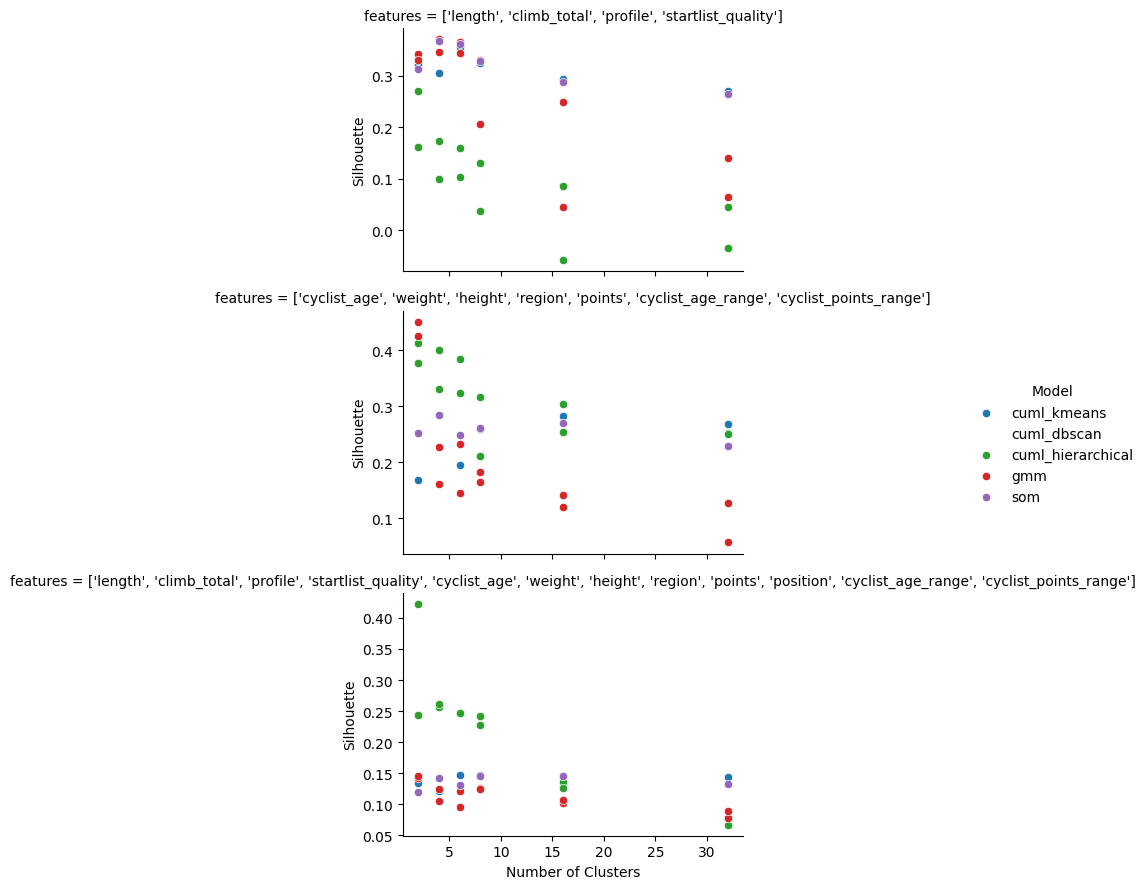

In [18]:
g = sns.FacetGrid(results, row='features', hue='model', sharey=False, height=3, aspect=1.5)
g.map(sns.scatterplot, 'clusters', 'silhouette')
g.add_legend(title='Model')
g.set_axis_labels('Number of Clusters', 'Silhouette')
plt.show()

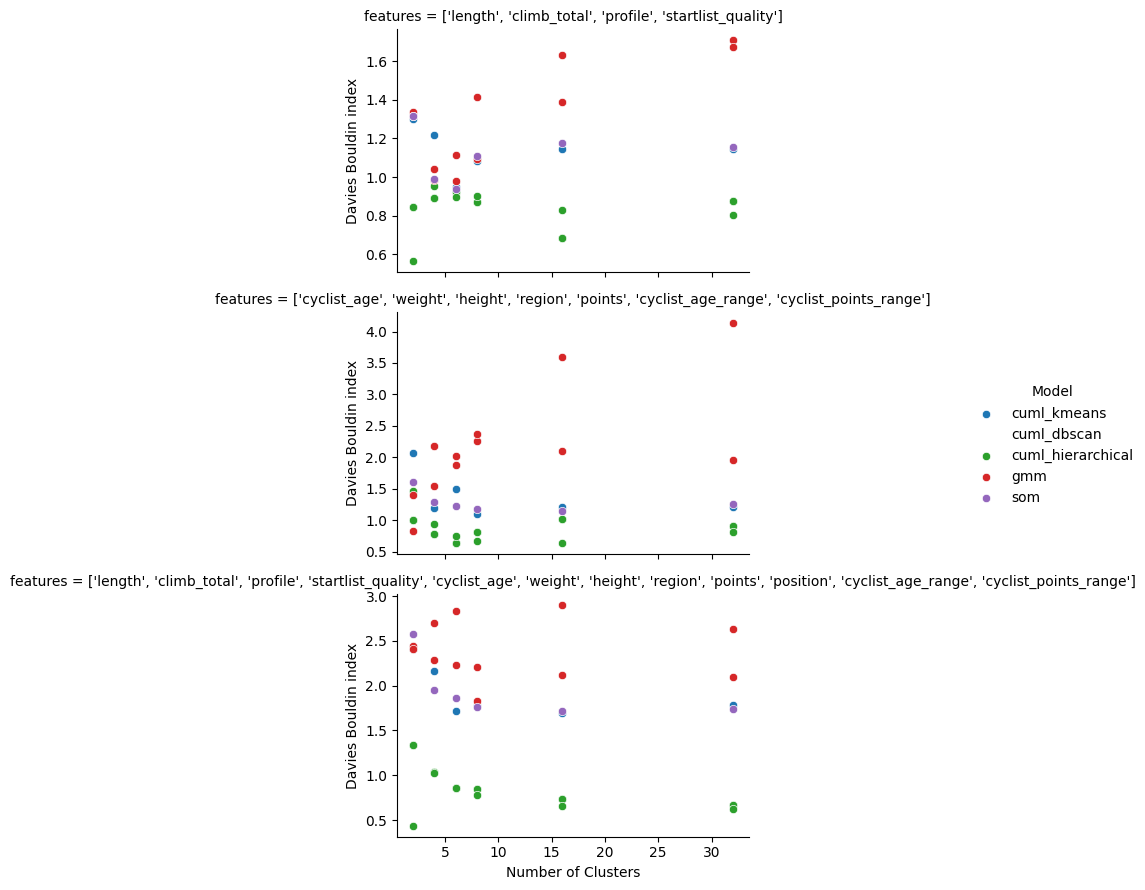

In [19]:
g = sns.FacetGrid(results, row='features', hue='model', sharey=False, height=3, aspect=1.5)
g.map(sns.scatterplot, 'clusters', 'davies_bouldin')
g.add_legend(title='Model')
g.set_axis_labels('Number of Clusters', 'Davies Bouldin index')
plt.show()

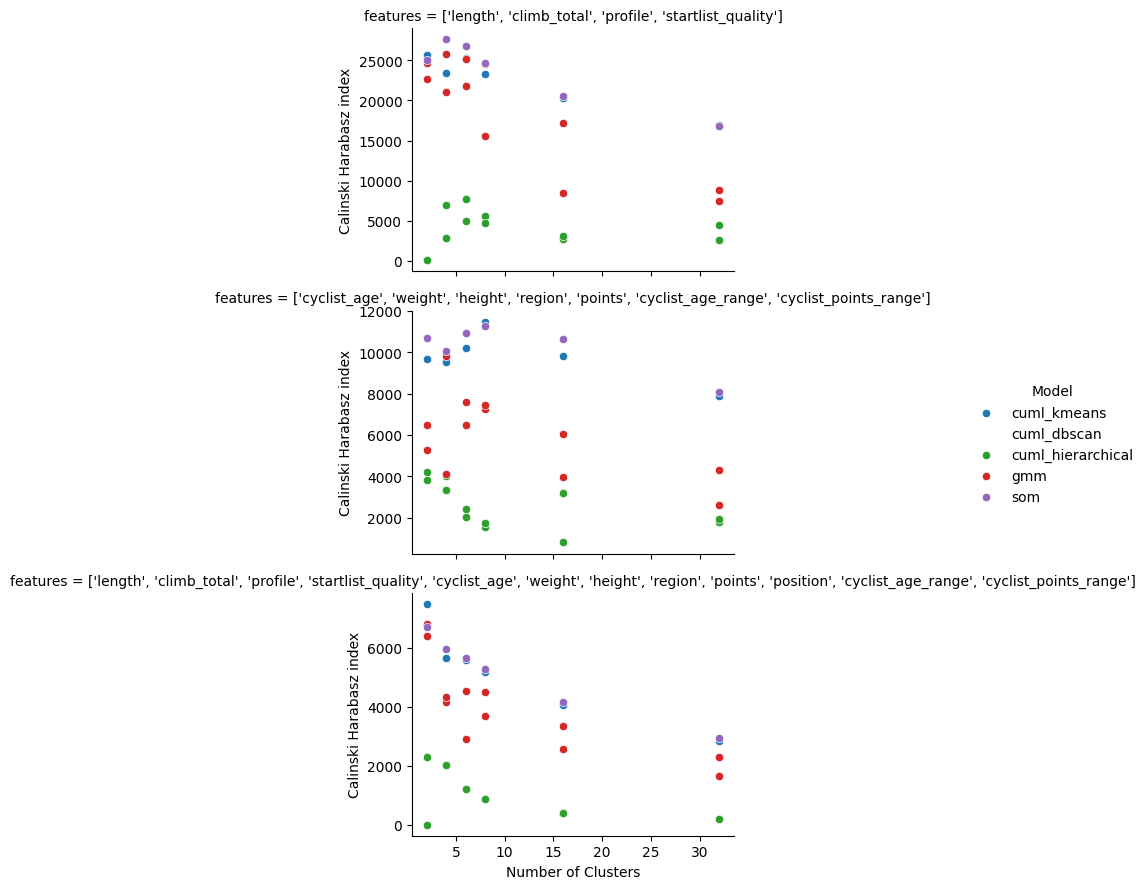

In [20]:
g = sns.FacetGrid(results, row='features', hue='model', sharey=False, height=3, aspect=1.5)
g.map(sns.scatterplot, 'clusters', 'calinski_harabasz')
g.add_legend(title='Model')
g.set_axis_labels('Number of Clusters', 'Calinski Harabasz index')
plt.show()

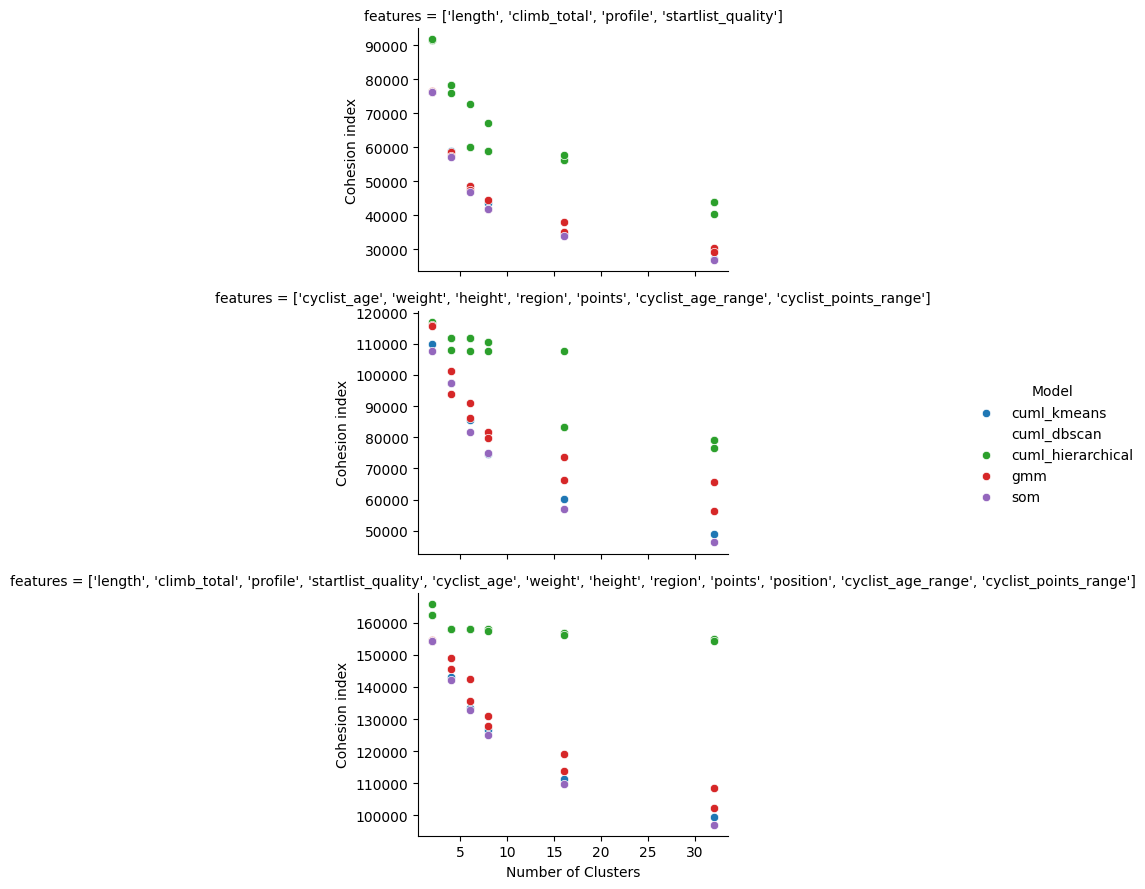

In [21]:
g = sns.FacetGrid(results, row='features', hue='model', sharey=False, height=3, aspect=1.5)
g.map(sns.scatterplot, 'clusters', 'cohesion')
g.add_legend(title='Model')
g.set_axis_labels('Number of Clusters', 'Cohesion index')
plt.show()

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

def visualize_clusters(data, model_dict):
    """
    Visualize clusters for each model in the provided dictionary.

    Parameters:
    - data: Original DataFrame containing the dataset.
    - model_dict: Dictionary containing model information with keys:
        - 'hyperparams': Hyperparameters of the model.
        - 'features': List of feature names used for clustering.
        - 'labels': Array of cluster labels assigned by the model.
        - 'model': The clustering model object.
    """
    for model_info in model_dict:
        features = model_info['features']
        labels = model_info['labels']
        model = model_info['model']
        model_name = type(model).__name__
        hyperparams = model_info['hyperparams']

        # Extract the subset of data used for clustering
        data_subset = data[features].values

        # # Standardize the data
        # scaler = StandardScaler()
        # data_scaled = scaler.fit_transform(data_subset)

        # Reduce dimensionality to 2D for visualization
        pca = PCA(n_components=2)
        data_pca = pca.fit_transform(data_subset)

        # Create a scatter plot
        plt.figure(figsize=(10, 6))
        scatter = plt.scatter(data_pca[:, 0], data_pca[:, 1], c=labels, cmap='viridis', alpha=0.6)
        plt.colorbar(scatter, label='Cluster Label')
        plt.title(f'Clusters Visualized for {model_name} with Hyperparameters: {hyperparams} with features: {features}')
        plt.xlabel('PCA Component 1')
        plt.ylabel('PCA Component 2')
        plt.grid(True)
        plt.show()


In [27]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.decomposition import PCA

def visualize_clusters_3d(data, model_info):

    features = model_info['features']
    labels = model_info['labels']
    model = model_info['model']
    model_name = type(model).__name__
    hyperparams = model_info['hyperparams']

    data_subset = data[features].values
    pca = PCA(n_components=3)
    data_pca = pca.fit_transform(data_subset)

    # Create a 3D scatter plot
    fig = plt.figure(figsize=(12, 8))
    ax = fig.add_subplot(111, projection='3d')
    scatter = ax.scatter(data_pca[:, 0], data_pca[:, 1], data_pca[:, 2], c=labels, cmap='viridis', alpha=0.6)
    legend1 = ax.legend(*scatter.legend_elements(), title="Clusters")
    ax.add_artist(legend1)
    ax.set_title(f'3D Cluster Visualization for {model_name}\nHyperparameters: {hyperparams}\nFeatures: {features}')
    ax.set_xlabel('PCA Component 1')
    ax.set_ylabel('PCA Component 2')
    ax.set_zlabel('PCA Component 3')
    plt.show()


In [8]:
original_df = reverse_center_and_scale(df, normalization_scalers_df)
original_df

,length,climb_total,profile,startlist_quality,cyclist_age,weight,height,region,points,cyclist_age_range,cyclist_points_range,position
0,203.0,-0.373253,2.0,699.0,131.664036,0.137758,0.063754,2.0,125.0,1.0,2.0,48.0
1,162.7,6.235097,2.0,970.0,135.483908,-1.459409,-1.693610,3.0,50.0,1.0,1.0,140.0
2,164.0,-0.373253,5.0,1148.0,135.483908,0.847610,0.063754,2.0,50.0,1.0,1.0,53.0
3,170.0,5.430397,4.0,861.0,185.142252,1.025073,0.239491,2.0,80.0,2.0,2.0,96.0
4,168.0,4.124349,2.0,1688.0,135.483908,-2.524186,-2.748028,2.0,100.0,1.0,2.0,18.0
...,...,...,...,...,...,...,...,...,...,...,...,...
49995,189.3,5.194254,2.0,960.0,127.844163,1.734925,2.172591,2.0,50.0,1.0,1.0,117.0
49996,176.0,2.235211,1.0,755.0,139.303781,-1.104483,0.415227,2.0,50.0,1.0,1.0,54.0
49997,189.0,5.306876,2.0,881.0,116.384545,-1.814335,-0.639191,2.0,80.0,0.0,2.0,174.0
49998,185.2,6.087962,2.0,817.0,127.844163,-0.394631,0.415227,2.0,50.0,1.0,1.0,176.0


### K-Means

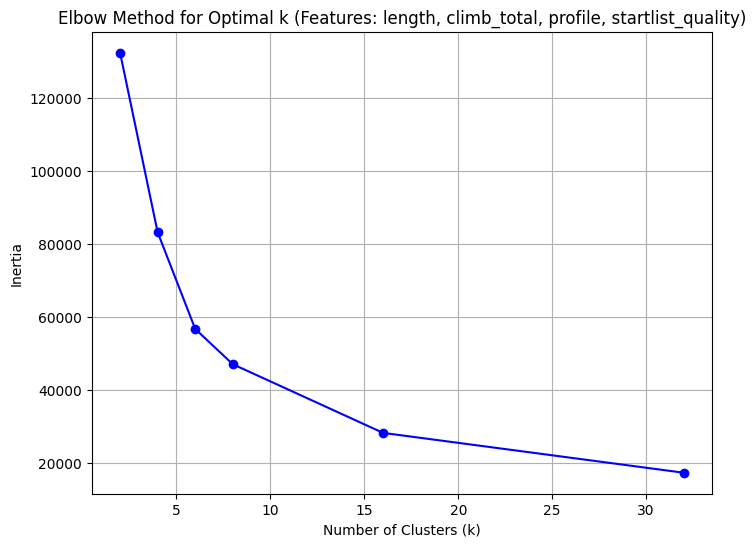

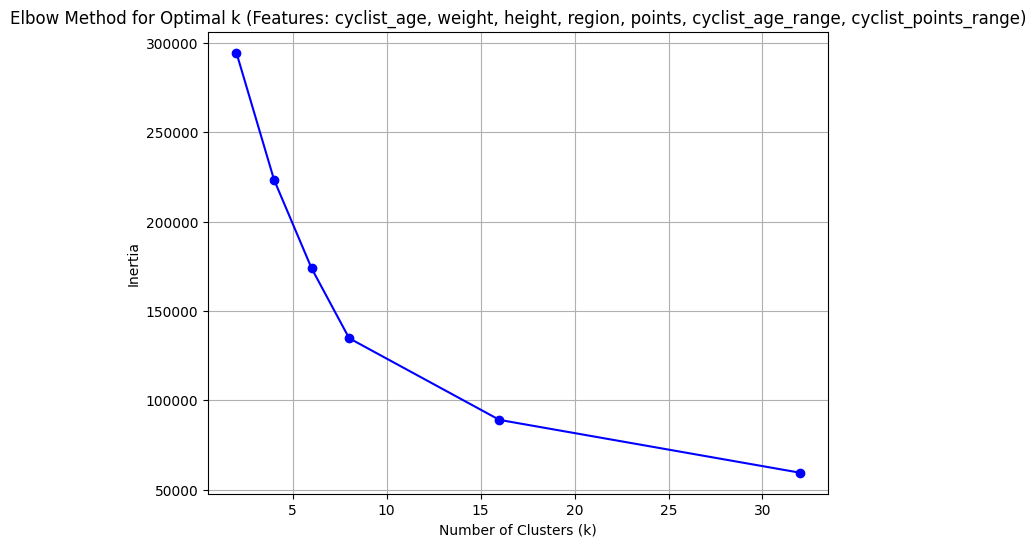

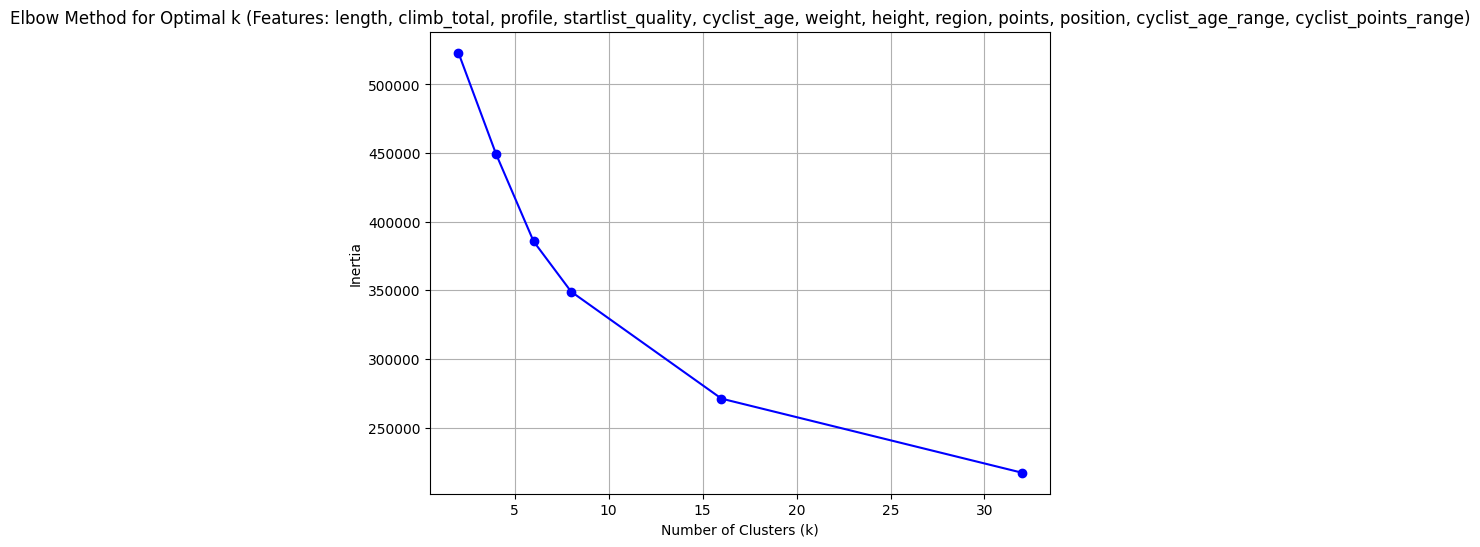

In [27]:
import matplotlib.pyplot as plt
from sklearn.metrics import pairwise_distances_argmin_min
from collections import defaultdict

grouped_by_features = defaultdict(list)
for result in dict_models['cuml_kmeans']:
    feature_set_tuple = tuple(result['features']) 
    grouped_by_features[feature_set_tuple].append(result)

for feature_set, models_for_feature_set in grouped_by_features.items():
    
    k_values = [result['hyperparams']['clusters'] for result in models_for_feature_set]
    inertia_values = [result['model'].inertia_ for result in models_for_feature_set]

    plt.figure(figsize=(8, 6))
    plt.plot(k_values, inertia_values, marker='o', linestyle='-', color='b')
    plt.title(f'Elbow Method for Optimal k (Features: {", ".join(feature_set)})')
    plt.xlabel('Number of Clusters (k)')
    plt.ylabel('Inertia')
    plt.grid(True)
    plt.show()


### DBSCAN

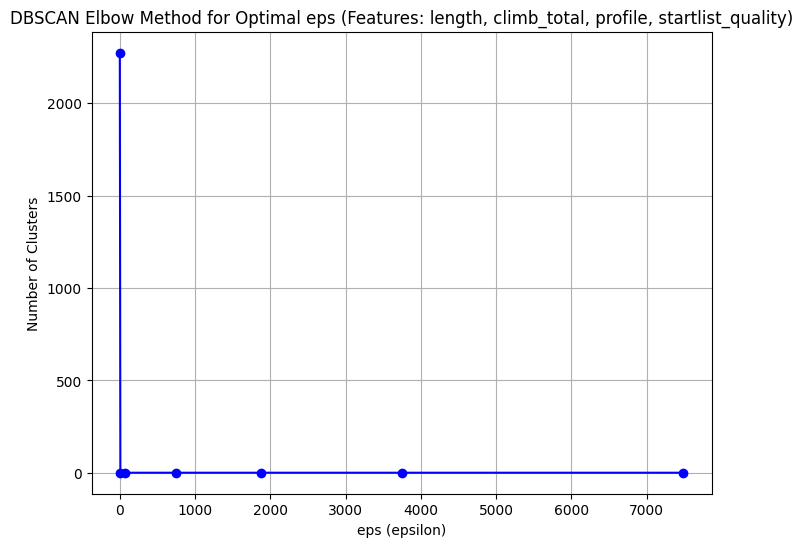

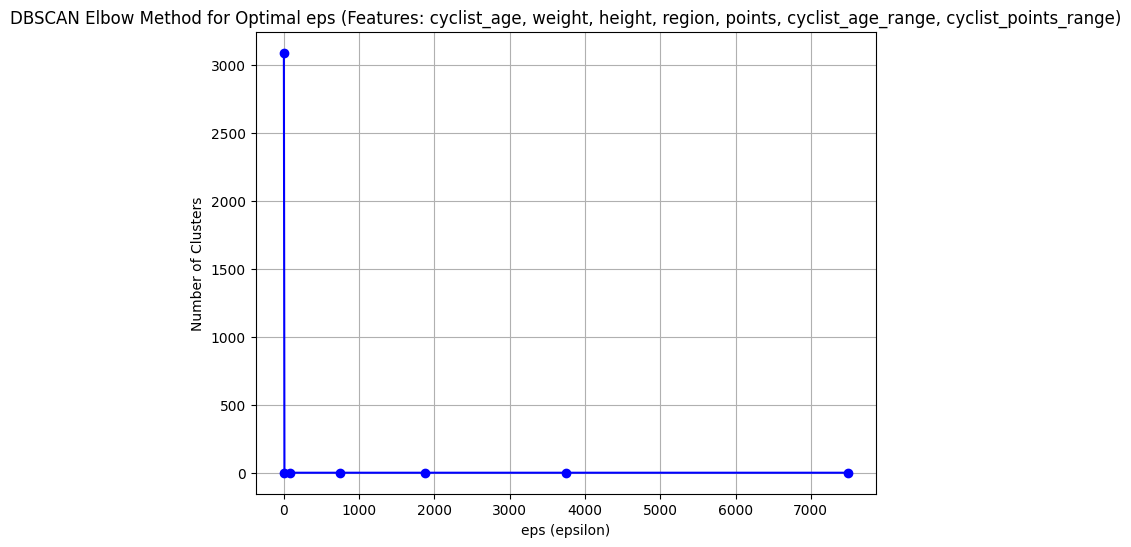

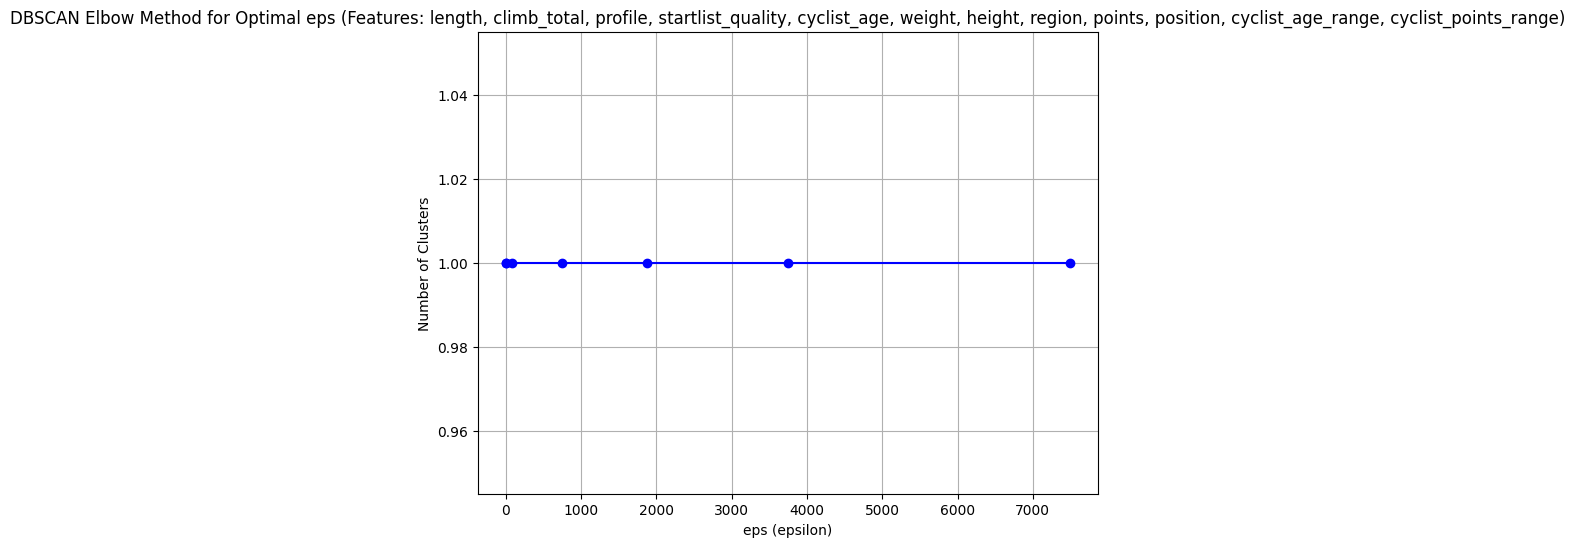

In [28]:
grouped_by_features = defaultdict(list)
for result in dict_models['cuml_dbscan']:
    feature_set_tuple = tuple(result['features'])  
    grouped_by_features[feature_set_tuple].append(result)


for feature_set, models_for_feature_set in grouped_by_features.items():
    eps_values = [result['hyperparams']['eps'] for result in models_for_feature_set]
    cluster_counts = []

    for result in models_for_feature_set:
        labels = result['labels']
        
        n_clusters = len(set(labels) - {-1}) 
        cluster_counts.append(n_clusters)

    plt.figure(figsize=(8, 6))
    plt.plot(eps_values, cluster_counts, marker='o', linestyle='-', color='b')
    plt.title(f'DBSCAN Elbow Method for Optimal eps (Features: {", ".join(feature_set)})')
    plt.xlabel('eps (epsilon)')
    plt.ylabel('Number of Clusters')
    plt.grid(True)
    plt.show()

### Agglomerative Clustering

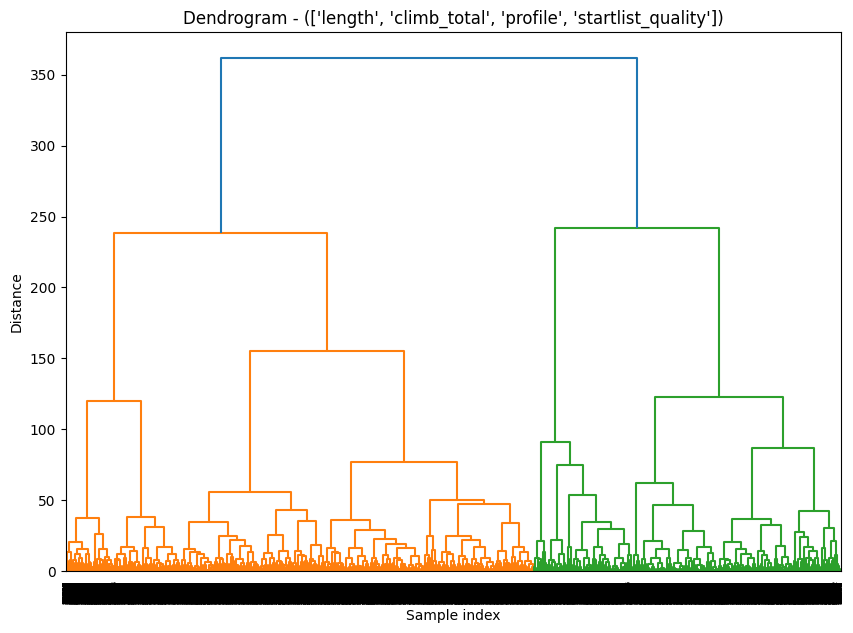

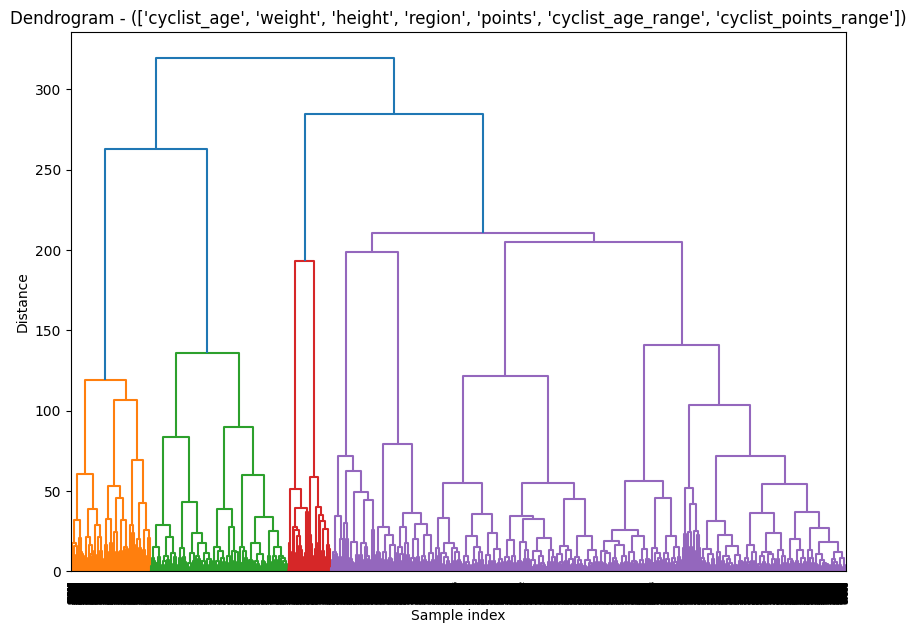

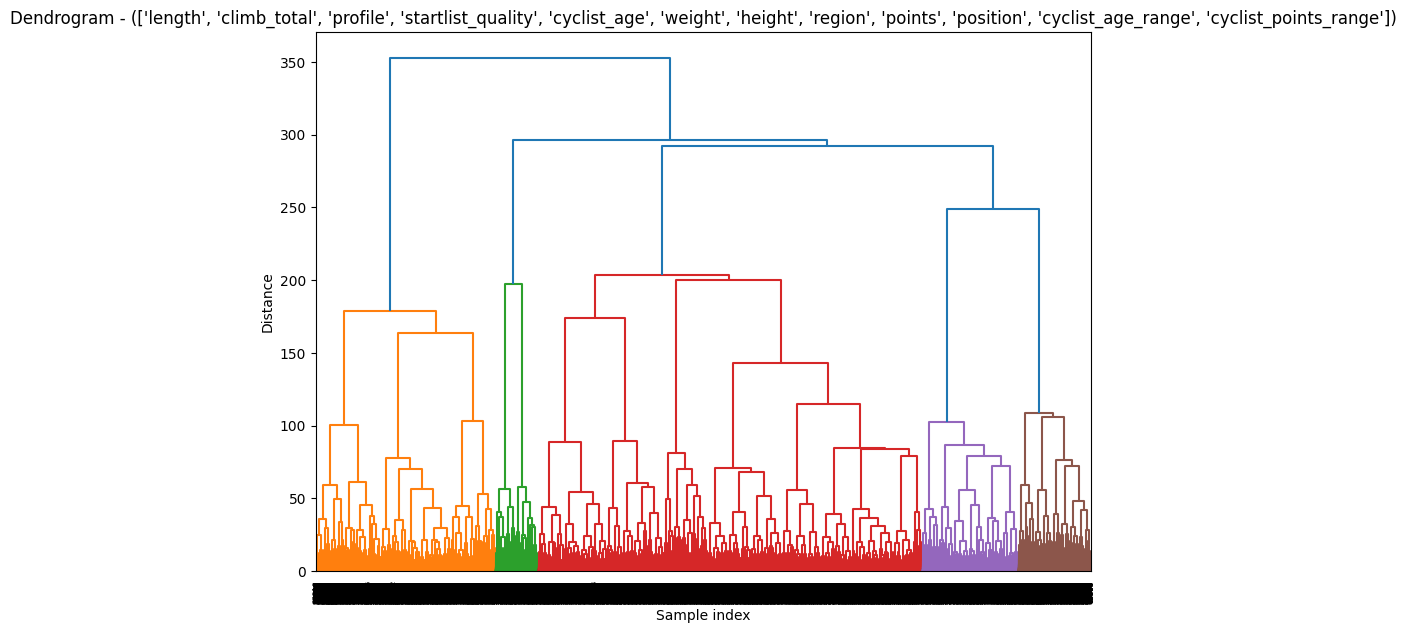

In [8]:
from scipy.cluster.hierarchy import dendrogram, linkage

for features in features_list:
    
    linkage_method = 'ward'
    Z = linkage(df[features], method=linkage_method)
    
    plt.figure(figsize=(10, 7))
    dendrogram(Z)
    plt.title(f'Dendrogram - ({features})')
    plt.xlabel('Sample index')
    plt.ylabel('Distance')
    plt.show()

## Analisys of clusters

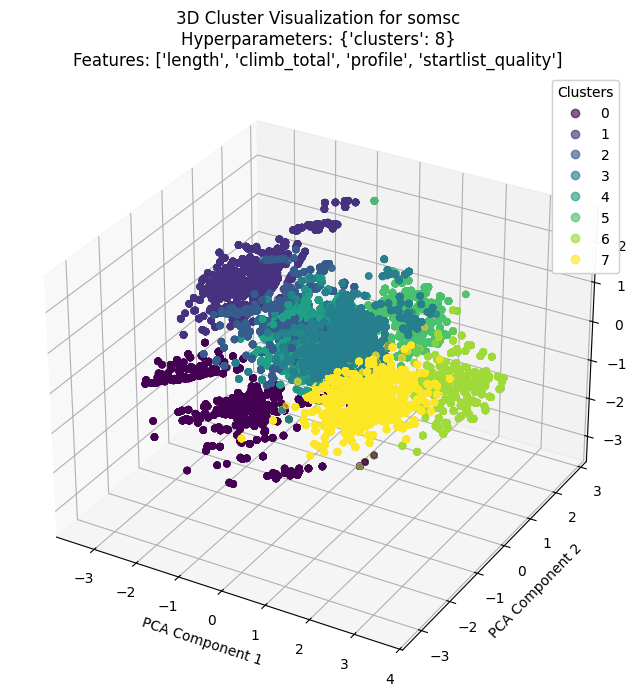

,length,climb_total,profile,startlist_quality,cluster
0,203.0,-0.373253,2.0,699.0,2
1,162.7,6.235097,2.0,970.0,3
2,164.0,-0.373253,5.0,1148.0,2
3,170.0,5.430397,4.0,861.0,7
4,168.0,4.124349,2.0,1688.0,5
...,...,...,...,...,...
49995,189.3,5.194254,2.0,960.0,3
49996,176.0,2.235211,1.0,755.0,4
49997,189.0,5.306876,2.0,881.0,3
49998,185.2,6.087962,2.0,817.0,3


In [31]:
som_list = dict_models['som']
labels = None

for model in som_list:
    if model['hyperparams']['clusters'] == 8 and sorted(model['features']) == sorted(['length', 'climb_total', 'profile', 'startlist_quality']):
        labels = model['labels']
        visualize_clusters_3d(df, model)
        break

race_df = original_df[['length', 'climb_total', 'profile', 'startlist_quality']].copy()
race_df['cluster'] = labels
race_df

In [14]:
for cluster, group in race_df.groupby("cluster"):
    print(f"Cluster {cluster} Summary:")
    print(group.describe())
    print("\n")

Cluster 0 Summary:
            length  climb_total      profile  startlist_quality  cluster
count  6351.000000  6351.000000  6351.000000        6351.000000   6351.0
mean     21.835213     1.404732     1.189104         977.719414      0.0
std      17.246245     1.192590     1.535095         295.600858      0.0
min       1.150000    -0.373253    -1.000000         156.000000      0.0
25%       8.000000    -0.373253     1.000000         799.000000      0.0
50%      16.400000     1.595810     1.000000         929.000000      0.0
75%      33.400000     2.153469     2.000000        1091.000000      0.0
max     104.500000     6.211483     5.000000        1812.000000      0.0


Cluster 1 Summary:
            length  climb_total      profile  startlist_quality  cluster
count  5481.000000  5481.000000  5481.000000        5481.000000   5481.0
mean    179.136544    -0.373253    -0.995621         868.103631      1.0
std      40.103714     0.000000     0.093488         206.954674      0.0
min      66

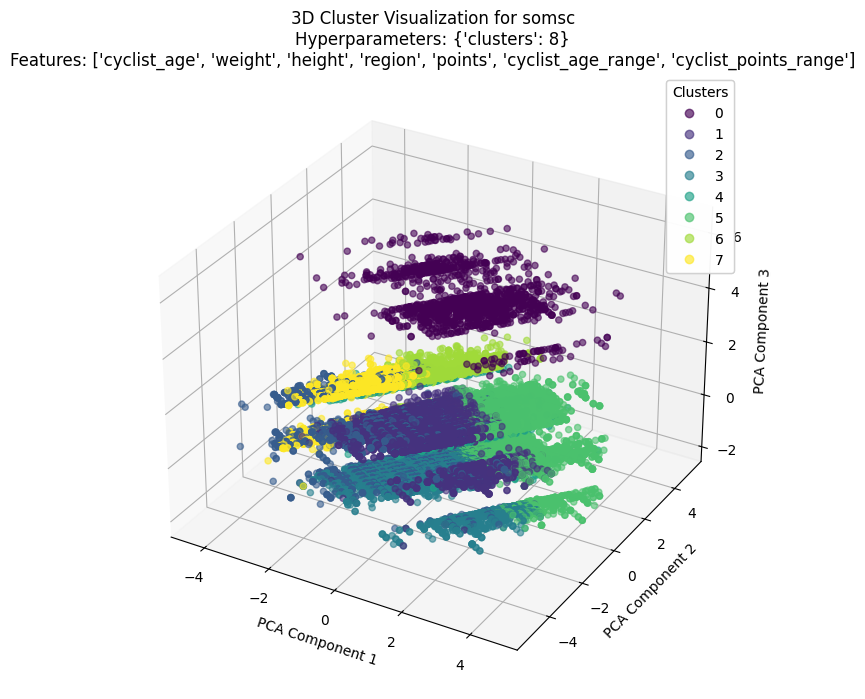

,cyclist_age,weight,height,region,points,cyclist_age_range,cyclist_points_range,cluster
0,131.664036,0.137758,0.063754,2.0,125.0,1.0,2.0,1
1,135.483908,-1.459409,-1.693610,3.0,50.0,1.0,1.0,3
2,135.483908,0.847610,0.063754,2.0,50.0,1.0,1.0,3
3,185.142252,1.025073,0.239491,2.0,80.0,2.0,2.0,5
4,135.483908,-2.524186,-2.748028,2.0,100.0,1.0,2.0,1
...,...,...,...,...,...,...,...,...
49995,127.844163,1.734925,2.172591,2.0,50.0,1.0,1.0,5
49996,139.303781,-1.104483,0.415227,2.0,50.0,1.0,1.0,3
49997,116.384545,-1.814335,-0.639191,2.0,80.0,0.0,2.0,7
49998,127.844163,-0.394631,0.415227,2.0,50.0,1.0,1.0,3


In [30]:
som_list = dict_models['som']
labels = None

for model in som_list:
    if model['hyperparams']['clusters'] == 8 and sorted(model['features']) == sorted(['cyclist_age', 'weight', 'height', 'region', 'points', 'cyclist_age_range', 'cyclist_points_range']):
        labels = model['labels']
        visualize_clusters_3d(df, model)
        break

cyclist_df = original_df[['cyclist_age', 'weight', 'height', 'region', 'points', 'cyclist_age_range', 'cyclist_points_range']].copy()
cyclist_df['cluster'] = labels
cyclist_df

In [18]:
for cluster, group in cyclist_df.groupby("cluster"):
    print(f"Cluster {cluster} Summary:")
    print(group.describe())
    print("\n")

Cluster 0 Summary:
       cyclist_age       weight       height       region       points  \
count  1294.000000  1294.000000  1294.000000  1294.000000  1294.000000   
mean    138.745855     0.184351     0.110795     2.129830   284.215611   
std      14.447906     1.031047     1.032011     0.600456    24.631528   
min     104.924928    -2.524186    -2.748028     0.000000   275.000000   
25%     127.844163    -0.572094    -0.639191     2.000000   275.000000   
50%     139.303781     0.137758     0.063754     2.000000   275.000000   
75%     146.943526     0.847610     0.766700     2.000000   275.000000   
max     181.322379     4.574332     3.402746     5.000000   350.000000   

       cyclist_age_range  cyclist_points_range  cluster  
count        1294.000000                1294.0   1294.0  
mean            0.846213                   3.0      0.0  
std             0.485200                   0.0      0.0  
min             0.000000                   3.0      0.0  
25%             1.000000

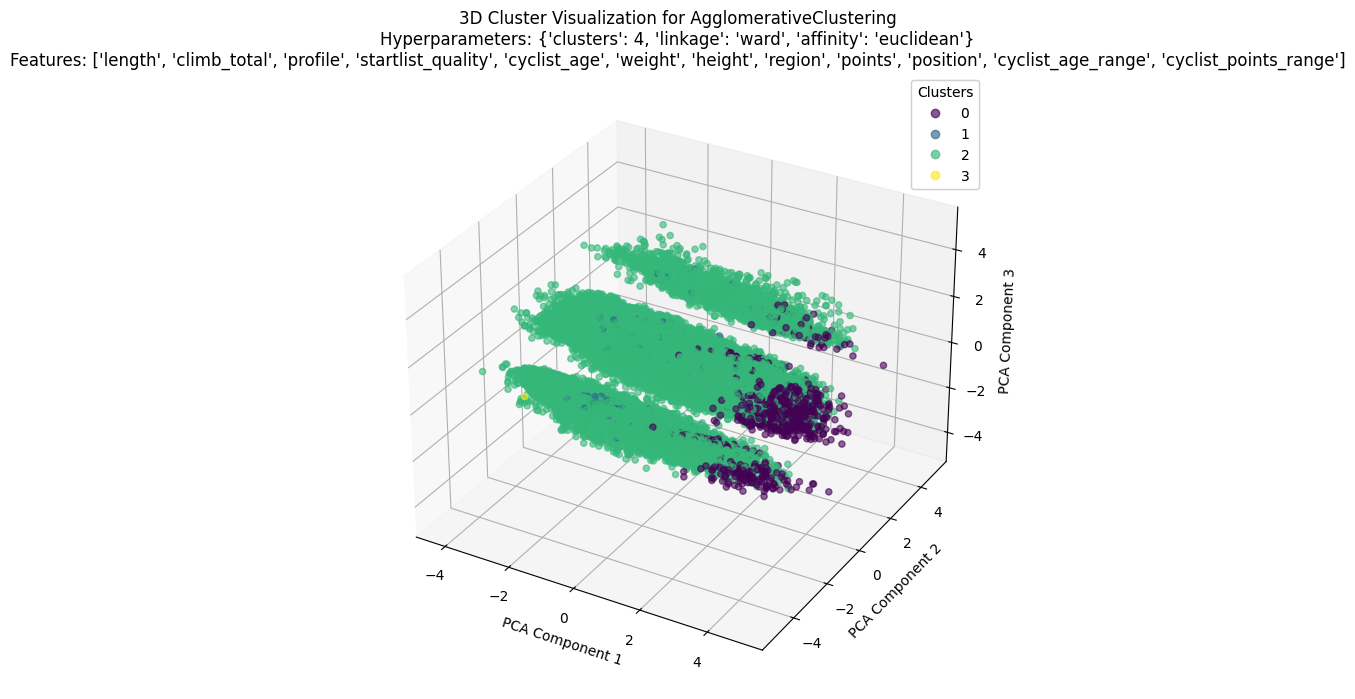

,length,climb_total,profile,startlist_quality,cyclist_age,weight,height,region,points,position,cyclist_age_range,cyclist_points_range,cluster
0,203.0,-0.373253,2.0,699.0,131.664036,0.137758,0.063754,2.0,125.0,48.0,1.0,2.0,2
1,162.7,6.235097,2.0,970.0,135.483908,-1.459409,-1.693610,3.0,50.0,140.0,1.0,1.0,2
2,164.0,-0.373253,5.0,1148.0,135.483908,0.847610,0.063754,2.0,50.0,53.0,1.0,1.0,2
3,170.0,5.430397,4.0,861.0,185.142252,1.025073,0.239491,2.0,80.0,96.0,2.0,2.0,2
4,168.0,4.124349,2.0,1688.0,135.483908,-2.524186,-2.748028,2.0,100.0,18.0,1.0,2.0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,189.3,5.194254,2.0,960.0,127.844163,1.734925,2.172591,2.0,50.0,117.0,1.0,1.0,2
49996,176.0,2.235211,1.0,755.0,139.303781,-1.104483,0.415227,2.0,50.0,54.0,1.0,1.0,2
49997,189.0,5.306876,2.0,881.0,116.384545,-1.814335,-0.639191,2.0,80.0,174.0,0.0,2.0,2
49998,185.2,6.087962,2.0,817.0,127.844163,-0.394631,0.415227,2.0,50.0,176.0,1.0,1.0,2


In [29]:
hierarchical_list = dict_models['cuml_hierarchical']
labels = None

for model in hierarchical_list:
    if model['hyperparams']['clusters'] == 4 and sorted(model['features']) == sorted(features_list[2]):
        visualize_clusters_3d(df, model)
        labels = model['labels']
        break

total_df = original_df[features_list[2]].copy()
total_df['cluster'] = labels
total_df

In [23]:
for cluster, group in total_df.groupby("cluster"):
    print(f"Cluster {cluster} Summary:")
    print(group.describe())
    print("\n")

Cluster 0 Summary:
            length  climb_total      profile  startlist_quality  cyclist_age  \
count  1294.000000  1294.000000  1294.000000        1294.000000  1294.000000   
mean    266.491808     3.386233     1.048686        1080.061051   138.745855   
std      17.295504     3.850478     1.390480         230.074298    14.447906   
min     241.000000    -0.373253    -1.000000         565.000000   104.924928   
25%     256.000000    -0.373253    -1.000000         887.000000   127.844163   
50%     260.000000     3.319648     2.000000        1122.000000   139.303781   
75%     273.000000     6.534816     2.000000        1253.000000   146.943526   
max     305.000000    10.196837     5.000000        1630.000000   181.322379   

            weight       height       region       points     position  \
count  1294.000000  1294.000000  1294.000000  1294.000000  1294.000000   
mean      0.184351     0.110795     2.129830   284.215611    56.698609   
std       1.031047     1.032011     0.